<a href="https://colab.research.google.com/github/mithulkannan17/Machine_learning_2/blob/main/bagging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET INFORMATION

Dataset loaded successfully!

Dataset Shape:
(768, 9)

First 5 Rows:
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   diabetes_pedigree_function  age  outcome  
0                       0.627   50        1  
1                       0.351   31        0  
2                       0.672   32        1  
3                       0.167   21        0  
4                       2.288   33        1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  -

<Figure size 1000x600 with 0 Axes>

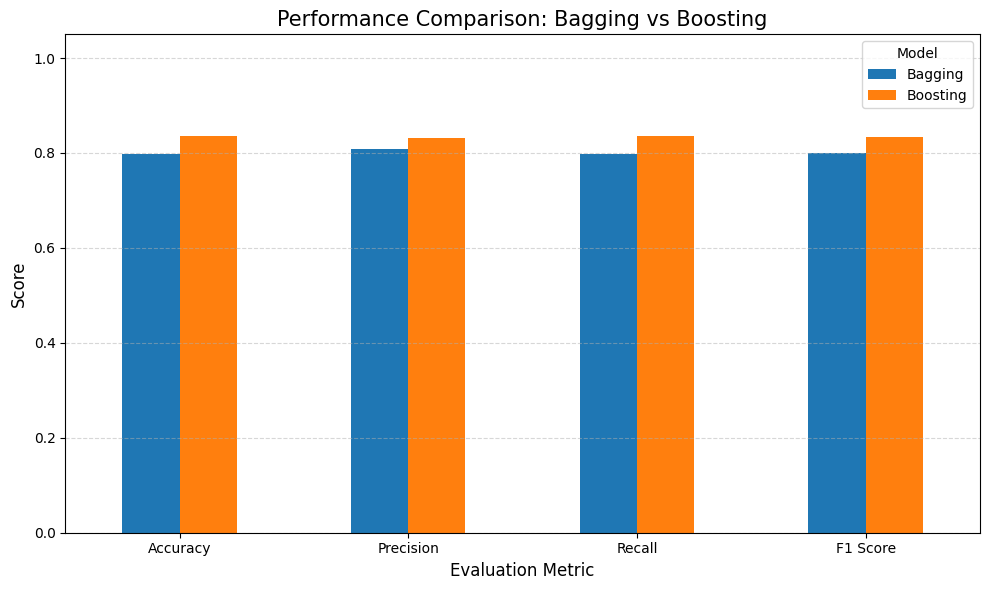

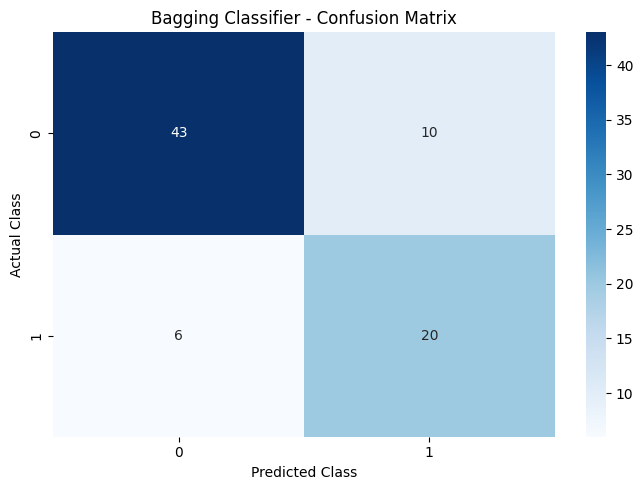

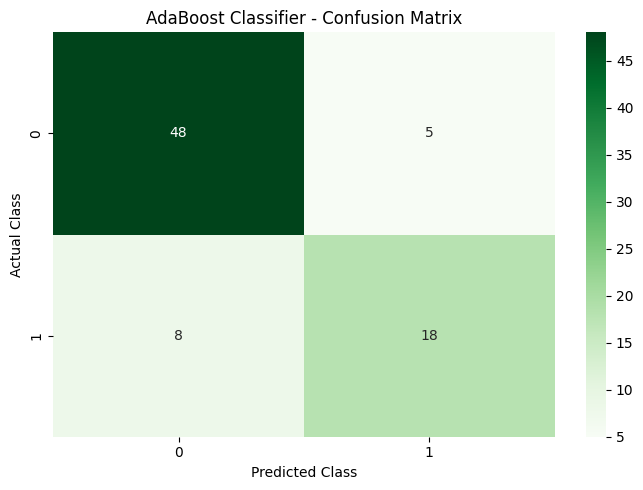

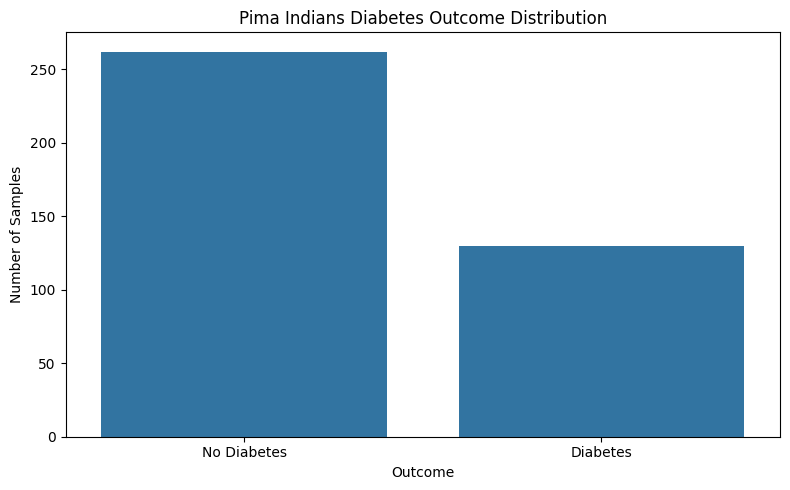


EXPERIMENT COMPLETED

The Pima Indians Diabetes Dataset was classified using two ensemble
learning techniques:

1. Bagging
2. AdaBoost (Boosting)

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score

The performance comparison is shown in the graph above.



In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

df = pd.read_csv(url, header=None)

feature_names = [
    "pregnancies", "glucose", "blood_pressure", "skin_thickness",
    "insulin", "bmi", "diabetes_pedigree_function", "age", "outcome"
]
df.columns = feature_names

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\nDataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# The Pima dataset often has 0s as placeholders for missing values
# in 'glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi'.
# Replace 0s with NaN for proper handling, then drop NaNs.
df[['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']] = \
    df[['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']].replace(0, pd.NA)

df = df.dropna()

print("\n" + "=" * 70)
print("AFTER HANDLING MISSING VALUES")
print("=" * 70)

print("\nNew Dataset Shape:")
print(df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

y = df["outcome"]

X = df.drop("outcome", axis=1)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y);

print("\n" + "=" * 70)
print("TARGET CLASSES")
print("=" * 70)

for number, name in enumerate(label_encoder.classes_):
    print(number, "=", name)

categorical_features = [

]

numerical_features = [
    "pregnancies", "glucose", "blood_pressure", "skin_thickness",
    "insulin", "bmi", "diabetes_pedigree_function", "age"
]


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ],
    remainder='passthrough' # Keep other columns, if any (though in this case there are none)
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 70)
print("TRAIN TEST SPLIT")
print("=" * 70)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train.shape)
print("Processed testing shape :", X_test.shape)

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train);

bagging_pred = bagging_model.predict(X_test);

boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

boosting_model.fit(X_train, y_train);

boosting_pred = boosting_model.predict(X_test);

def evaluate_model(model_name, y_test, predictions):

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[str(c) for c in label_encoder.classes_],
            zero_division=0
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            y_test,
            predictions
        )
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

bagging_results = evaluate_model(
    "BAGGING CLASSIFIER",
    y_test,
    bagging_pred
)

boosting_results = evaluate_model(
    "ADABOOST CLASSIFIER",
    y_test,
    boosting_pred
)

comparison = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ],

        "Bagging": [
            bagging_results["Accuracy"],
            bagging_results["Precision"],
            bagging_results["Recall"],
            bagging_results["F1 Score"]
        ],

        "Boosting": [
            boosting_results["Accuracy"],
            boosting_results["Precision"],
            boosting_results["Recall"],
            boosting_results["F1 Score"]
        ]
    }
)


print("\n" + "=" * 70)
print("FINAL PERFORMANCE COMPARISON")
print("=" * 70)

print(
    comparison.to_string(
        index=False,
        formatters={
            "Bagging": "{:.4f}".format,
            "Boosting": "{:.4f}".format
        }
    )
)


plt.figure(figsize=(10, 6))

comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Performance Comparison: Bagging vs Boosting",
    fontsize=15
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=12
)

plt.ylabel(
    "Score",
    fontsize=12
)

plt.ylim(0, 1.05)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Model"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.show()

bagging_cm = confusion_matrix(
    y_test,
    bagging_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    bagging_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[str(c) for c in label_encoder.classes_],
    yticklabels=[str(c) for c in label_encoder.classes_]
)

plt.title(
    "Bagging Classifier - Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()

boosting_cm = confusion_matrix(
    y_test,
    boosting_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    boosting_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[str(c) for c in label_encoder.classes_],
    yticklabels=[str(c) for c in label_encoder.classes_]
)

plt.title(
    "AdaBoost Classifier - Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()

plt.figure(figsize=(8, 5))

sns.countplot(
    x=df["outcome"].map({0: "No Diabetes", 1: "Diabetes"})
)

plt.title(
    "Pima Indians Diabetes Outcome Distribution"
)

plt.xlabel(
    "Outcome"
)

plt.ylabel(
    "Number of Samples"
)

plt.tight_layout()

plt.show()

print("\n" + "=" * 70)
print("EXPERIMENT COMPLETED")
print("=" * 70)

print("""
The Pima Indians Diabetes Dataset was classified using two ensemble
learning techniques:

1. Bagging
2. AdaBoost (Boosting)

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score

The performance comparison is shown in the graph above.
""")